# Stock Market ML Trading System: ETF Signals and Backtesting

**Research notebook** for the DataTalks.Club *Stock Markets Analytics Zoomcamp 2026* project.

This notebook runs the **whole research workflow** by calling the project modules, in order:

1. download and validate real data (Yahoo Finance, FRED, Kenneth French library);
2. build the feature table with a strict no-look-ahead contract;
3. explore the data and check the leakage guards numerically;
4. train and compare seven models with chronological splits;
5. select the probability threshold on the **validation** window only;
6. backtest four long-only strategies against a like-for-like benchmark;
7. produce the latest **simulated** signal and refresh the reports.

> **This is a simulation.** No broker is contacted, no order is sent, there is no
> leverage and no short selling. Nothing here is investment advice.

Timing rule used everywhere: at the close of session *t* we only know data up to
*t*; the label is the **next** session's open-to-close return, so a signal is
executed at the next open and closed at that session's close.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

import config
from src import backtest, build_features, download_data, plots, train_models
from src.utils import read_json

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

print(config.PROJECT_TITLE)
print("Universe      :", config.TICKERS)
print("Study window  :", config.STUDY_START, "->", config.TEST_END or "last completed session")
print("Train / Val   :", config.TRAIN_START, "/", config.VALID_START)
print("Cost bps/side :", config.COMMISSION_BPS + config.SLIPPAGE_BPS)
print("Random seed   :", config.RANDOM_SEED)
print("Project root  :", ROOT)

Stock Market ML Trading System: ETF Signals and Backtesting
Universe      : ['SPY', 'QQQ', 'IWM', 'XLK', 'XLF', 'XLE']
Study window  : 2015-01-01 -> last completed session
Train / Val   : 2015-01-01 / 2020-01-01
Cost bps/side : 3.0
Random seed   : 42
Project root  : <project-root>


## 1. Data: download, validate, cache

`src.download_data.update_cache()` refreshes the parquet cache incrementally
(only the last 15 calendar days are re-requested per ticker) and records the
retrieval timestamp, the data cutoff, row counts and every cleaning decision in
`data/raw/manifest.json` and `data/raw/validation.json`.

Set `LIVE = False` to reuse the local cache with **zero** HTTP requests.

In [2]:
LIVE = True  # False -> no network access, reuse data/raw

if LIVE:
    manifest = download_data.update_cache()
else:
    manifest = read_json(download_data.MANIFEST_PATH, default={})

validation = read_json(download_data.VALIDATION_PATH, default={})

pd.Series(
    {
        "data_cutoff": manifest.get("data_cutoff"),
        "retrieval_timestamp_utc": manifest.get("retrieval_timestamp_utc"),
        "raw_ohlcv_rows_clean": manifest.get("rows_clean_total"),
        "sessions_total": manifest.get("sessions_total"),
        "duplicates_dropped": validation.get("dropped_duplicates"),
        "impossible_bars_dropped": validation.get("dropped_inconsistent_bars"),
        "non_positive_prices_dropped": validation.get("dropped_non_positive_or_non_finite"),
        "incomplete_current_date_dropped": validation.get("dropped_incomplete_current_date"),
        "zero_volume_bars": validation.get("zero_volume_rows"),
    }
)

2026-11-15 19:40:56 | INFO    | Incremental update from 2026-10-29 (overlap 15 days)


2026-11-15 19:40:56 | INFO    | Downloading OHLCV for SPY,QQQ,IWM,XLK,XLF,XLE from 2026-10-29


2026-11-15 19:40:57 | INFO    | Downloaded 72 raw OHLCV rows


2026-11-15 19:41:03 | INFO    | Macro series: 3379 rows, last date 2026-11-12


2026-11-15 19:41:06 | INFO    | French factors: 3226 rows, last date 2026-09-30


2026-11-15 19:41:06 | INFO    | Cache updated: 19548 clean rows, cutoff 2026-11-13, 3258 sessions


data_cutoff                                  2026-11-13
retrieval_timestamp_utc            2026-11-16T00:40:56Z
raw_ohlcv_rows_clean                              19548
sessions_total                                     3258
duplicates_dropped                                    0
impossible_bars_dropped                               0
non_positive_prices_dropped                           0
incomplete_current_date_dropped                       0
zero_volume_bars                                      0
dtype: object

In [3]:
per_ticker = pd.DataFrame(validation.get("per_ticker", {})).T
per_ticker

,rows,first_date,last_date,missing_close,max_abs_daily_close_jump
IWM,3258,2013-12-02,2026-11-13,0,0.132669
QQQ,3258,2013-12-02,2026-11-13,0,0.120031
SPY,3258,2013-12-02,2026-11-13,0,0.109424
XLE,3258,2013-12-02,2026-11-13,0,0.201411
XLF,3258,2013-12-02,2026-11-13,0,0.137093
XLK,3258,2013-12-02,2026-11-13,0,0.13814


## 2. Features and labels

`src.build_features.build_features()` combines the three sources into the single
`(date, ticker)` table, adds the technical, market, macro and factor features,
creates the dummies and applies the chronological splits with a label embargo.

The full feature list is documented in `docs/data_dictionary.md` and exported to
`data/processed/features_metadata.json`.

In [4]:
sample, metadata = build_features.build_features()

print(f"modelling rows      : {len(sample):,}")
print(f"sessions            : {sample['date'].nunique():,}")
print(f"numeric features    : {metadata['n_numeric']}")
print(f"dummy features      : {metadata['n_dummies']}")
print(f"targets (TO_PREDICT): {metadata['to_predict']}")

sample[
    [
        "date",
        "ticker",
        "close",
        "ret_5d",
        "vol_20d",
        "rsi_14",
        "vix_lag1",
        "ff_mkt_rf_lag5",
        "target_ret_next_oc",
        "target_up",
        "split",
    ]
].tail(8)

2026-11-15 19:41:07 | INFO    | Features saved: 17892 modelling rows, 57 numeric + 23 dummy features


modelling rows      : 17,892
sessions            : 2,982
numeric features    : 57
dummy features      : 23
targets (TO_PREDICT): ['target_up', 'target_ret_next_oc']


,date,ticker,close,ret_5d,vol_20d,rsi_14,vix_lag1,ff_mkt_rf_lag5,target_ret_next_oc,target_up,split
17884,2026-11-11,XLF,58.630001,-0.009628,0.216068,62.711237,19.46,-0.0026,-0.011379,0.0,test
17885,2026-11-11,XLK,174.360001,-0.012125,0.454835,43.043707,19.46,-0.0026,0.023079,1.0,test
17886,2026-11-12,IWM,278.440002,0.027530,0.257286,48.821965,17.49,-0.0026,-0.005055,0.0,test
17887,2026-11-12,QQQ,688.169983,0.063550,0.361782,45.392260,17.49,-0.0026,-0.012563,0.0,test
17888,2026-11-12,SPY,757.119995,0.032906,0.223678,48.550533,17.49,-0.0026,-0.007499,0.0,test
17889,2026-11-12,XLE,64.330002,0.043810,0.317985,46.893858,17.49,-0.0026,0.000770,1.0,test
17890,2026-11-12,XLF,58.209999,0.012348,0.215951,59.451038,17.49,-0.0026,0.001365,1.0,test
17891,2026-11-12,XLK,173.770004,0.070144,0.454742,42.520639,17.49,-0.0026,-0.019011,0.0,test


In [5]:
split_table = pd.DataFrame(metadata["split_info"]["boundaries"]).T
split_table[
    ["signal_start", "signal_end", "trade_start", "trade_end", "rows", "sessions", "class_balance_up", "dropped_at_boundary"]
]

,signal_start,signal_end,trade_start,trade_end,rows,sessions,class_balance_up,dropped_at_boundary
train,2015-01-02,2019-12-30,2015-01-05,2019-12-31,7542,1257,0.521612,6
validation,2020-01-02,2022-12-29,2020-01-03,2022-12-30,4530,755,0.515011,6
test,2023-01-03,2026-11-12,2023-01-04,2026-11-13,5820,970,0.534536,0


## 3. Exploratory data analysis (real downloaded data)

All figures below are produced by `src.plots` from the actual feature table:
price history, class balance by ETF and year, correlation with the target
(computed on the **training window only**), the lagged-VIX relationship and
feature distributions.

2026-11-15 19:41:07 | INFO    | Saved 01_prices_normalized.png


2026-11-15 19:41:07 | INFO    | Saved 02_target_balance.png


2026-11-15 19:41:08 | INFO    | Saved 03_feature_correlation.png


2026-11-15 19:41:08 | INFO    | Saved 04_vix_relationship.png


2026-11-15 19:41:09 | INFO    | Saved 05_feature_distributions.png


prices


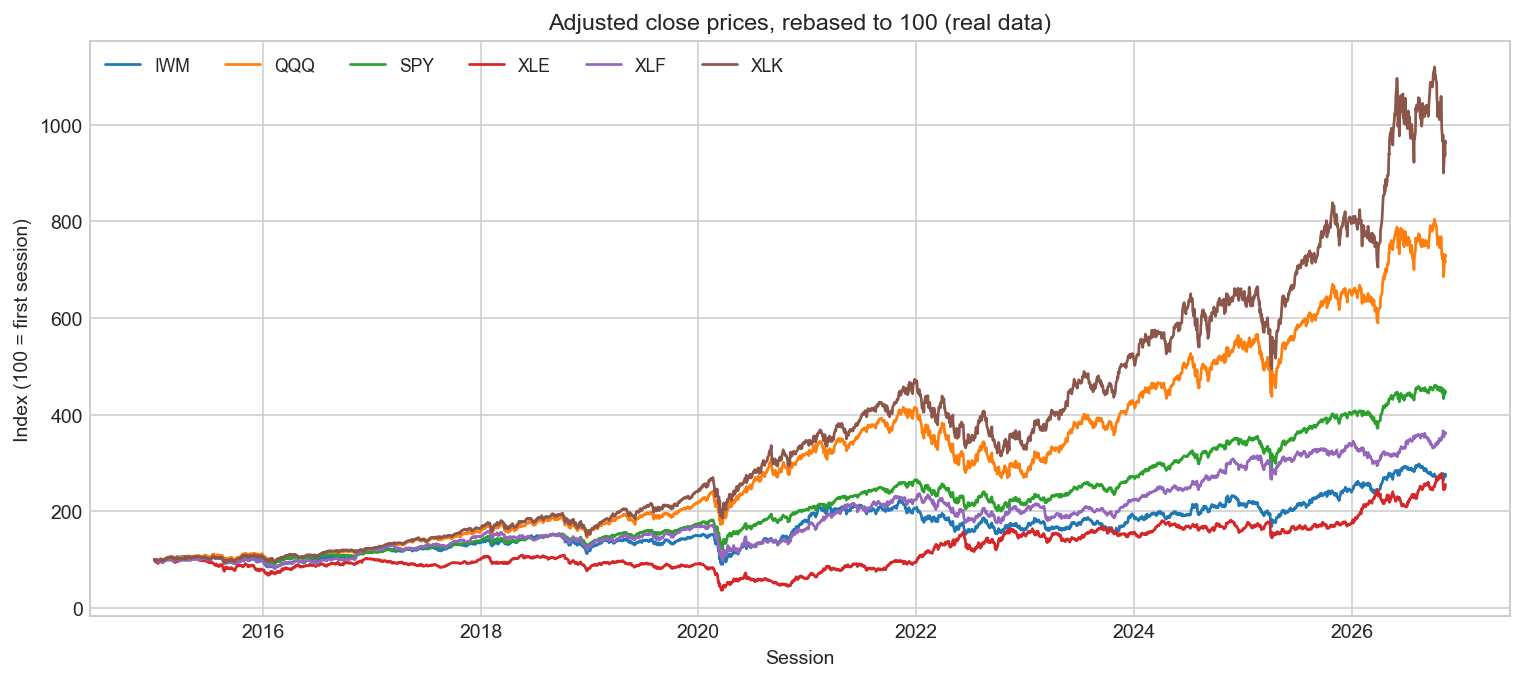

target_balance


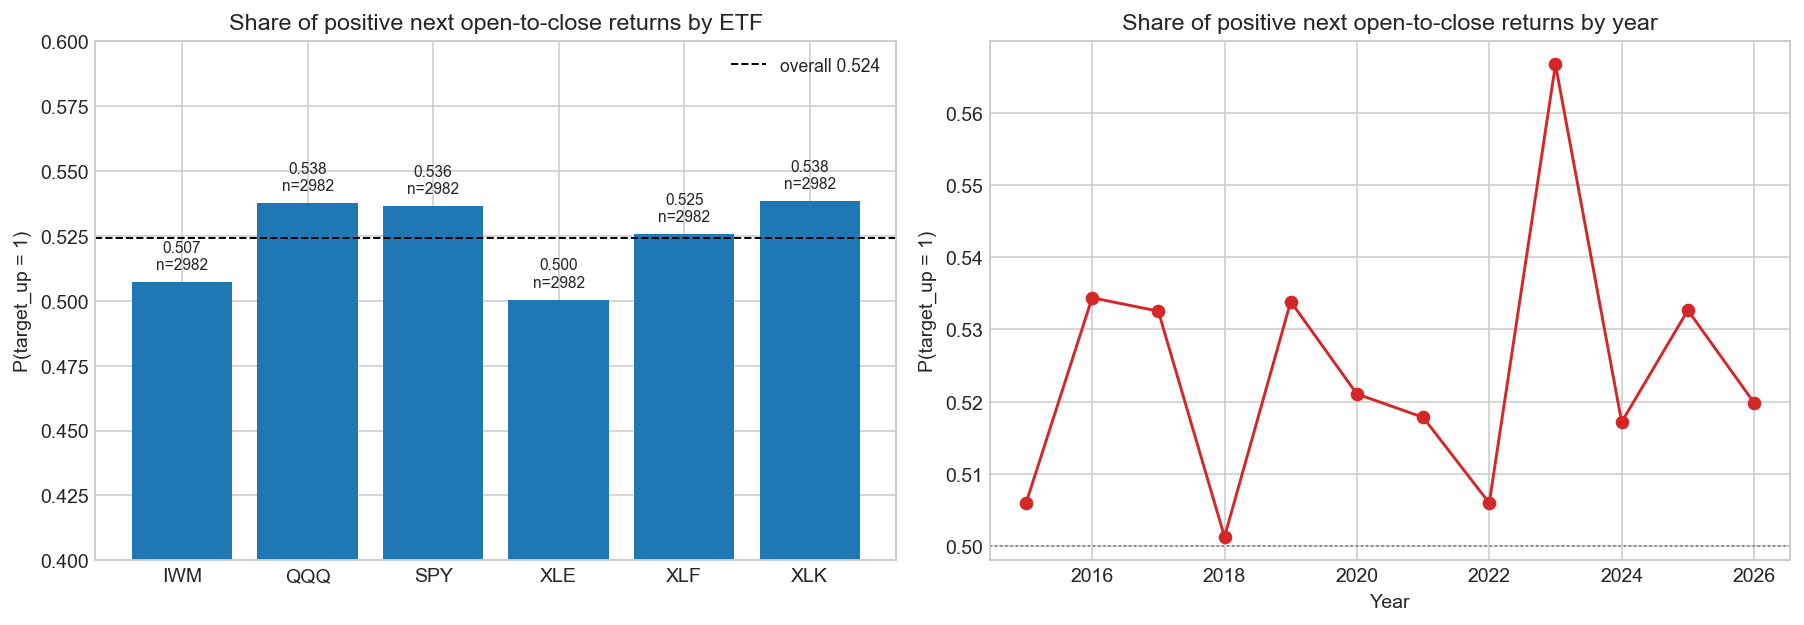

feature_correlation


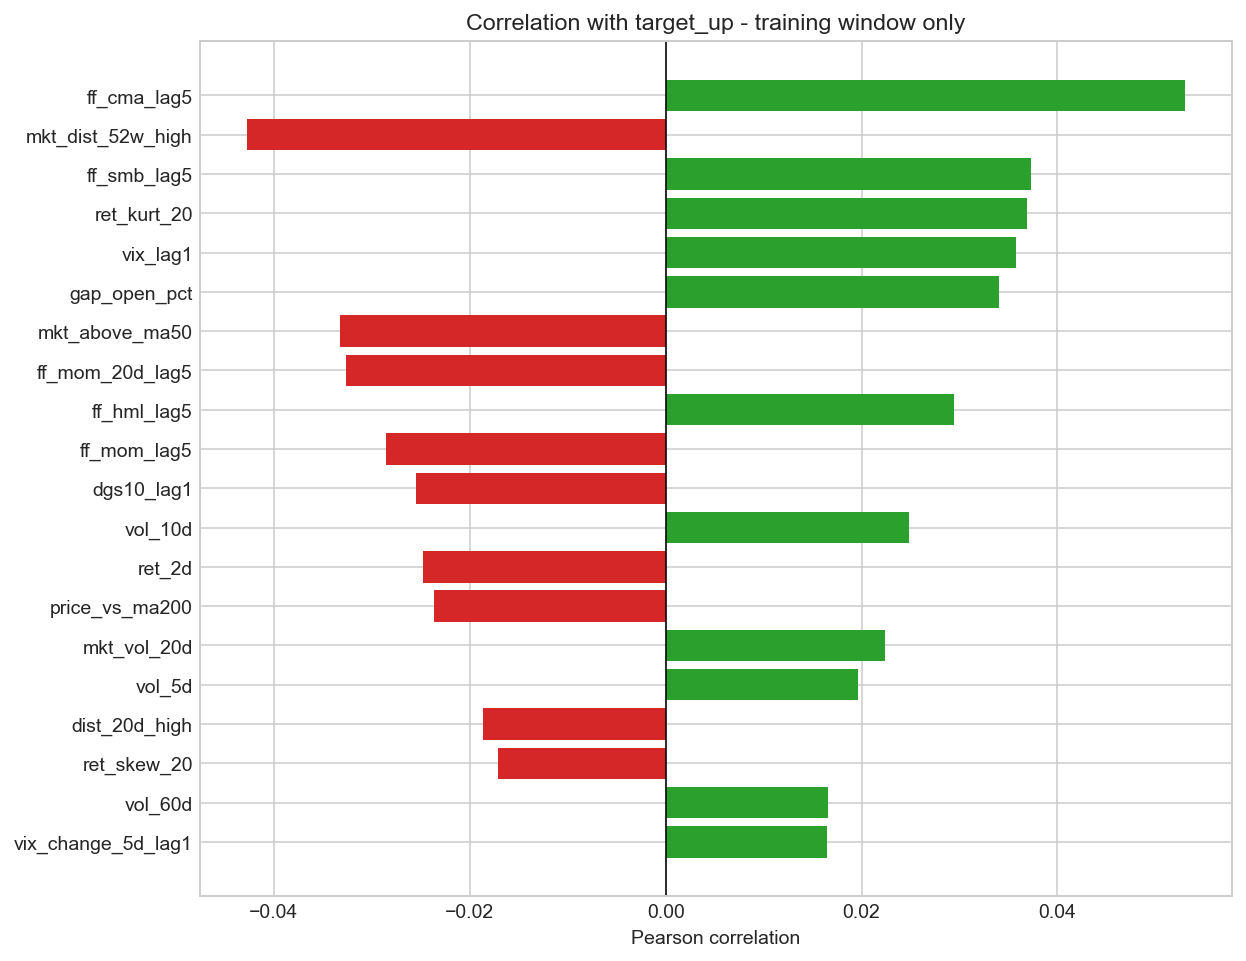

vix


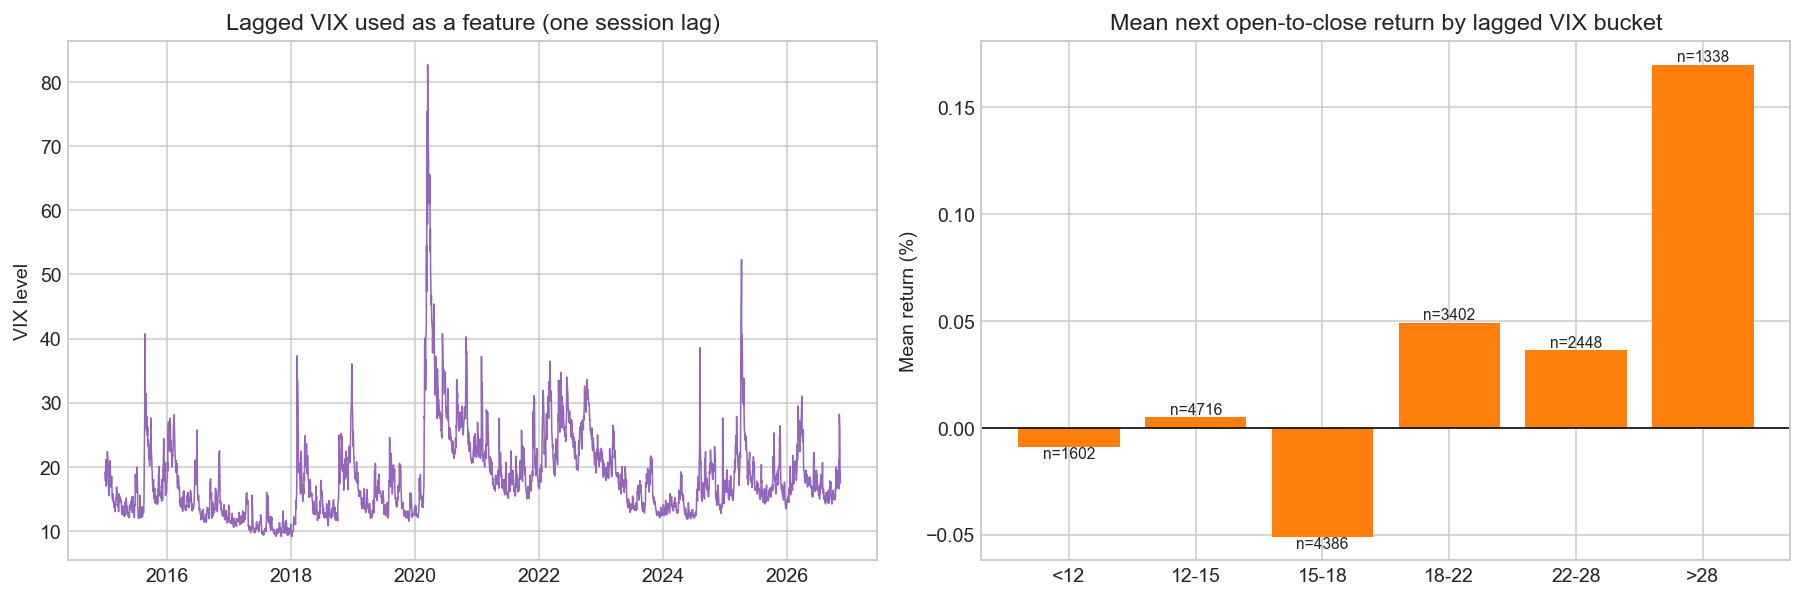

distributions


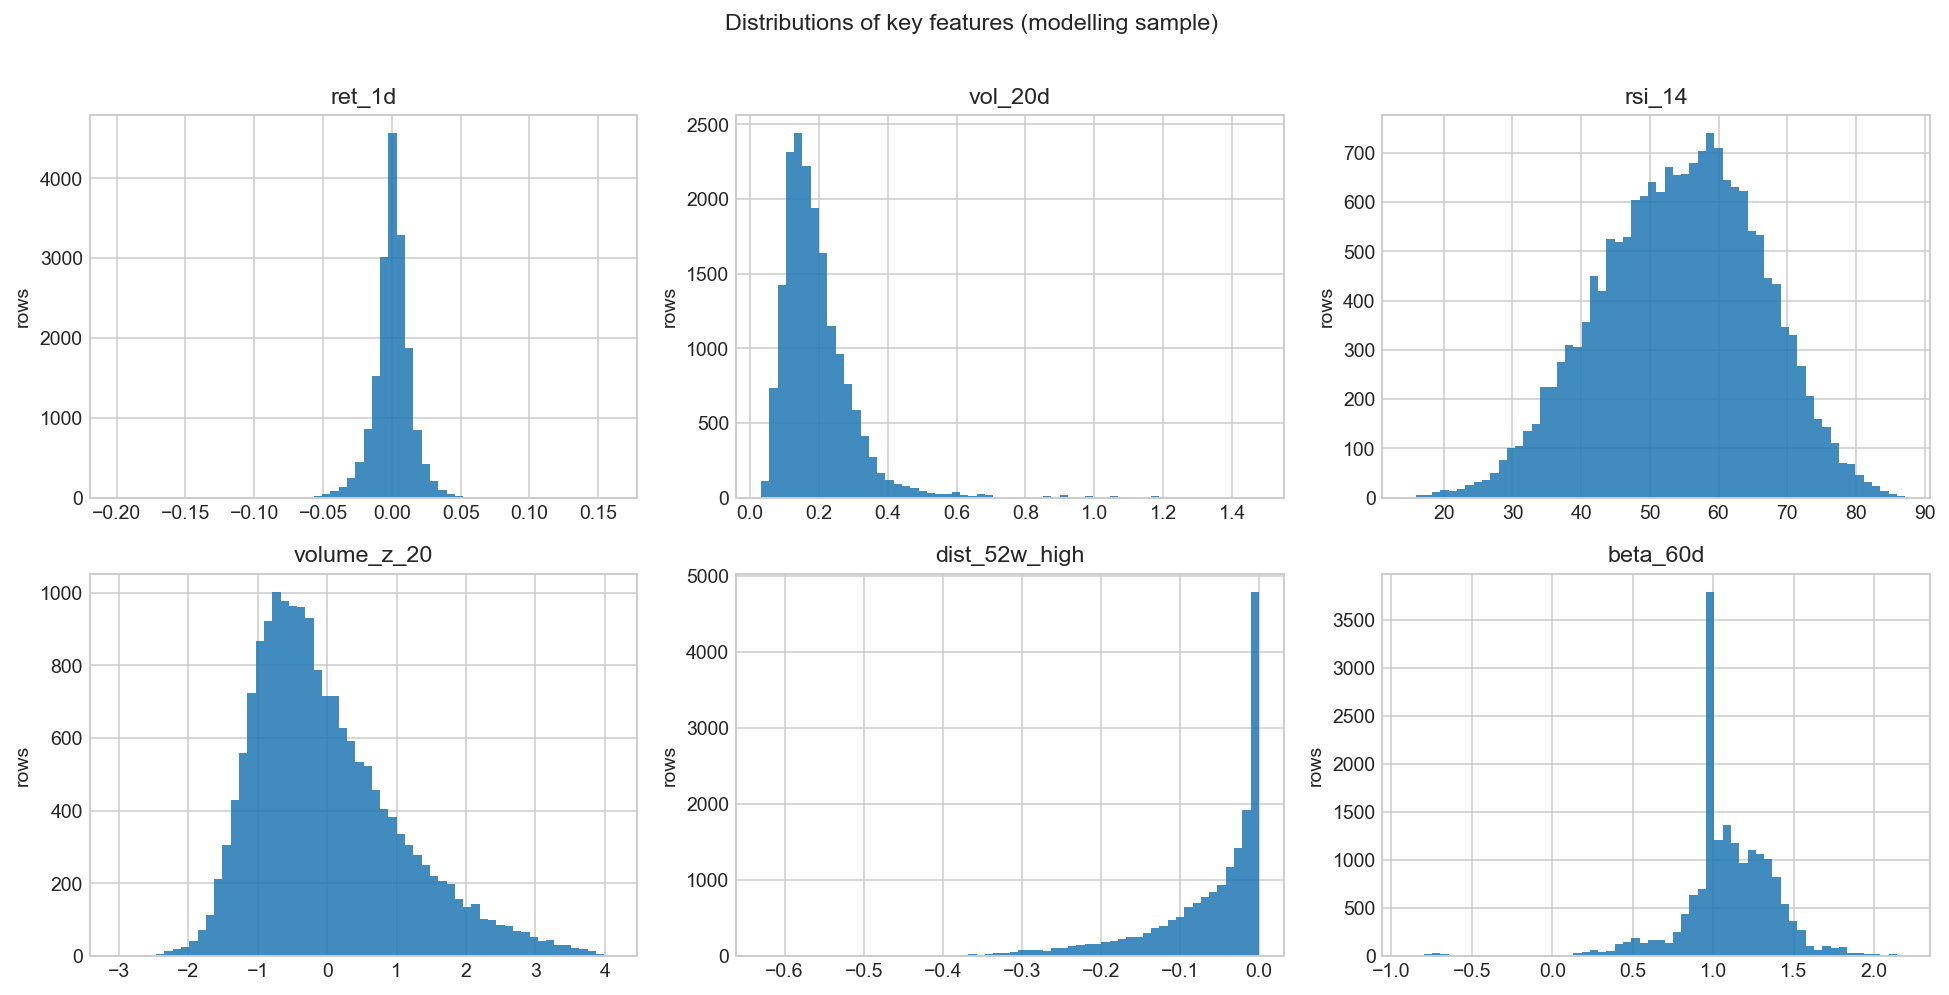

In [6]:
eda_figures = plots.make_eda_figures(sample, metadata)
for label, relative_path in eda_figures.items():
    print(label)
    display(Image(filename=str(ROOT / relative_path), width=950))

## 4. Leakage guard: rebuild the features with the future deleted

If a feature secretly used future prices, rebuilding the table with everything
after a cutoff removed would change the earlier values. The next cell rebuilds
the full panel on truncated inputs and prints the maximum absolute difference
for a sample of features. It must be zero.

In [7]:
ohlcv, macro, factors, _ = build_features.load_raw_cache()
cutoff = pd.Timestamp("2024-01-01")

full_panel, _ = build_features.build_feature_panel(ohlcv, macro, factors)
truncated_panel, _ = build_features.build_feature_panel(
    ohlcv[ohlcv["date"] < cutoff],
    macro[macro["date"] < cutoff],
    factors[factors["date"] < cutoff],
)

check_columns = metadata["numeric_features"][:15]
left = full_panel[full_panel["date"] < cutoff].set_index(["date", "ticker"])[check_columns]
right = truncated_panel[truncated_panel["date"] < cutoff].set_index(["date", "ticker"])[check_columns]
difference = (left - right).abs().max().sort_values(ascending=False)

print("max absolute difference between the full and the truncated build:")
print(difference.head(15))
assert difference.max() < 1e-9, "features change when future data is removed"
print("\nOK: no feature depends on future data.")

max absolute difference between the full and the truncated build:
ret_1d              0.0
ret_2d              0.0
ret_3d              0.0
ret_5d              0.0
ret_10d             0.0
ret_20d             0.0
ret_60d             0.0
ret_120d            0.0
vol_5d              0.0
vol_10d             0.0
vol_20d             0.0
vol_60d             0.0
downside_vol_20d    0.0
ma_ratio_5_20       0.0
ma_ratio_20_60      0.0
dtype: float64

OK: no feature depends on future data.


## 5. Models

`src.train_models.train_all()` fits seven models on the training window only:
two baselines, DecisionTree, RandomForest, logistic regression, XGBoost and a
small MLP.  Hyper-parameters are tuned with `GridSearchCV` and a date-grouped
time-series split (embargo of one session), scoring ROC-AUC.  Imputation and
scaling live inside each sklearn pipeline, so they are fitted on training rows
only.

In [8]:
artifacts = train_models.train_all(sample, metadata, tune=True)
predictions = artifacts["predictions"]

pd.DataFrame(
    {
        "seconds": pd.Series(artifacts["timings"]),
        "best_cv_roc_auc": pd.Series({k: v.get("best_cv_roc_auc") for k, v in artifacts["cv_results"].items()}),
    }
)

2026-11-15 19:41:10 | INFO    | Training baseline_majority ...


2026-11-15 19:41:10 | INFO    | baseline_majority done in 0.0s


2026-11-15 19:41:10 | INFO    | Training baseline_momentum ...


2026-11-15 19:41:10 | INFO    | baseline_momentum done in 0.0s


2026-11-15 19:41:10 | INFO    | Training decision_tree ...


2026-11-15 19:41:17 | INFO    | decision_tree done in 7.1s


... (5 outputs left out)

2026-11-15 19:41:41 | INFO    | xgboost done in 8.1s


2026-11-15 19:41:41 | INFO    | Training mlp ...


2026-11-15 19:41:45 | INFO    | mlp done in 4.7s


,seconds,best_cv_roc_auc
baseline_majority,0.00,NaN
baseline_momentum,0.00,NaN
decision_tree,7.14,0.513422
logistic_regression,0.50,0.504906
mlp,4.65,0.509779
random_forest,14.61,0.508303
xgboost,8.14,0.508648


In [9]:
print("best parameters (tuned on the training window):")
for model, params in artifacts["best_params"].items():
    if params:
        print(f"  {model}: {params}")

best parameters (tuned on the training window):
  decision_tree: {'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 200}
  random_forest: {'model__max_depth': 6, 'model__max_features': 0.3, 'model__min_samples_leaf': 100}
  logistic_regression: {'model__C': 0.01}
  xgboost: {'model__max_depth': 5, 'model__n_estimators': 200}
  mlp: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (32,)}


In [10]:
thresholds = {}
validation_predictions = predictions[predictions["split"] == "validation"]
validation_sessions = pd.DatetimeIndex(sorted(validation_predictions["trade_date"].unique()))

for model in train_models.MODEL_NAMES:
    if model not in validation_predictions.columns:
        continue
    thresholds[model] = backtest.select_threshold(
        train_models.for_backtest(validation_predictions, model),
        validation_sessions,
        cost_bps_side=config.COMMISSION_BPS + config.SLIPPAGE_BPS,
    )

best_model = max(thresholds, key=lambda m: thresholds[m]["selected"]["net_total_return"])
best_threshold = thresholds[best_model]["selected_threshold"]
print(f"Selected model: {best_model}   threshold: {best_threshold:.2f}")
print("Selection rule:", thresholds[best_model]["selection_rule"])

Selected model: xgboost   threshold: 0.70
Selection rule: maximise net cumulative return of S1 on the validation window subject to >= 100 trades; thresholds 0.50-0.70


## 6. Threshold selection on the validation window

The threshold maximises **net** cumulative return of the S1 rule on the
validation window, subject to at least 100 trades.  The test window is not used
here - it is evaluated once, further down.

In [11]:
pd.DataFrame(thresholds[best_model]["candidates"]).round(4)

,threshold,trades,net_total_return,sharpe
0,0.50,680,-0.0964,-0.0310
1,0.51,664,-0.1512,-0.1238
2,0.52,648,-0.1239,-0.0799
3,0.53,630,-0.0673,0.0095
4,0.54,614,-0.0223,0.0777
5,0.55,603,-0.0123,0.0920
6,0.56,588,0.0363,0.1634
7,0.57,569,0.1252,0.2894
8,0.58,548,0.1731,0.3549
9,0.59,529,0.2873,0.5050


In [12]:
ranking = pd.Series(
    {model: info["selected"]["net_total_return"] for model, info in thresholds.items()},
    name="validation_net_return",
).sort_values(ascending=False)
ranking.to_frame().assign(
    threshold=[thresholds[m]["selected_threshold"] for m in ranking.index],
    validation_trades=[thresholds[m]["selected"]["trades"] for m in ranking.index],
)

,validation_net_return,threshold,validation_trades
xgboost,0.628939,0.70,273
logistic_regression,0.213932,0.61,350
random_forest,0.005224,0.56,261
decision_tree,-0.064732,0.65,187
mlp,-0.304402,0.51,694
baseline_momentum,-0.419964,0.70,626
baseline_majority,-0.599693,0.70,755


In [13]:
classification = train_models.evaluate_predictions(
    predictions, {m: info["selected_threshold"] for m, info in thresholds.items()}
)

rows = []
for model, splits in classification.items():
    block = splits["test"]["at_selected_threshold"]
    rows.append(
        {
            "model": model,
            "threshold": block["threshold"],
            "accuracy": block["accuracy"],
            "precision": block["precision"],
            "recall": block["recall"],
            "f1": block["f1"],
            "roc_auc": block["roc_auc"],
            "brier": block.get("brier_score"),
            "predicted_up_share": block["predicted_positive_rate"],
        }
    )
pd.DataFrame(rows).set_index("model").round(4)

,threshold,accuracy,precision,recall,f1,roc_auc,brier,predicted_up_share
model,,,,,,,,
baseline_majority,0.70,0.5345,0.5345,1.0000,0.6967,0.5000,0.4655,1.0000
baseline_momentum,0.70,0.5014,0.5309,0.5773,0.5531,0.4957,0.4986,0.5813
decision_tree,0.65,0.4710,0.5314,0.0871,0.1497,0.5012,0.2659,0.0876
random_forest,0.56,0.4730,0.6048,0.0408,0.0765,0.5130,0.2514,0.0361
logistic_regression,0.61,0.4763,0.6329,0.0482,0.0896,0.5186,0.2749,0.0407
xgboost,0.70,0.4660,0.5093,0.0264,0.0501,0.5110,0.2677,0.0277
mlp,0.51,0.4973,0.5576,0.2880,0.3798,0.5162,0.3973,0.2761


## 7. Backtest on the untouched test window

Four long-only strategies (at most one ETF per session, flat at the close) are
simulated row by row with full compounding, and every position pays commission
and slippage on both entry and exit:

| Strategy | Rule |
| --- | --- |
| `S1_top_probability` | highest-probability ETF if `p >= threshold` |
| `S2_conservative` | `p >= threshold + 0.05` and lagged VIX <= 25 |
| `S3_trend_filter` | `p >= threshold + 0.02` and SPY above its 50-day average |
| `S4_risk_managed` | probability-scaled size + 1% intraday stop loss |

In [14]:
test_predictions = predictions[predictions["split"] == "test"]
test_sessions = pd.DatetimeIndex(sorted(test_predictions["trade_date"].unique()))
cost_bps_side = config.COMMISSION_BPS + config.SLIPPAGE_BPS

best_test_predictions = train_models.for_backtest(test_predictions, best_model)
suite = backtest.run_suite(best_test_predictions, test_sessions, best_threshold, cost_bps_side)

trades = backtest.predictions_to_trades(best_test_predictions)
benchmark_oc = backtest.benchmark_intraday(trades, test_sessions, cost_bps_side=cost_bps_side)
spy_closes = (
    sample[sample["ticker"] == config.BENCHMARK_TICKER]
    .set_index("trade_date")["close_next"]
    .reindex(test_sessions)
    .dropna()
)
benchmark_bh = backtest.benchmark_buy_and_hold(spy_closes, cost_bps_side=cost_bps_side)

performance = backtest.performance_table(
    suite,
    {
        "BENCHMARK SPY open-to-close (net)": benchmark_oc,
        "SPY buy & hold (different period)": benchmark_bh,
    },
)
performance[
    ["strategy", "total_return", "cagr", "sharpe_ratio", "max_drawdown", "total_trades", "win_rate", "exposure_share_of_sessions"]
].set_index("strategy").round(4)

,total_return,cagr,sharpe_ratio,max_drawdown,total_trades,win_rate,exposure_share_of_sessions
strategy,,,,,,,
S1_top_probability,0.1905,0.0463,0.6345,-0.0590,63.0,0.5079,0.0649
S2_conservative,0.0360,0.0092,0.4363,-0.0235,22.0,0.5000,0.0227
S3_trend_filter,0.0388,0.0099,0.3663,-0.0570,32.0,0.5000,0.0330
S4_risk_managed,0.1917,0.0466,0.6430,-0.0520,63.0,0.5079,0.0649
BENCHMARK SPY open-to-close (net),-0.2615,-0.0760,-0.5593,-0.3541,NaN,NaN,1.0000
SPY buy & hold (different period),1.0597,0.2067,1.3230,-0.1876,NaN,NaN,0.9990


2026-11-15 19:42:04 | INFO    | Saved 11_equity_curves.png


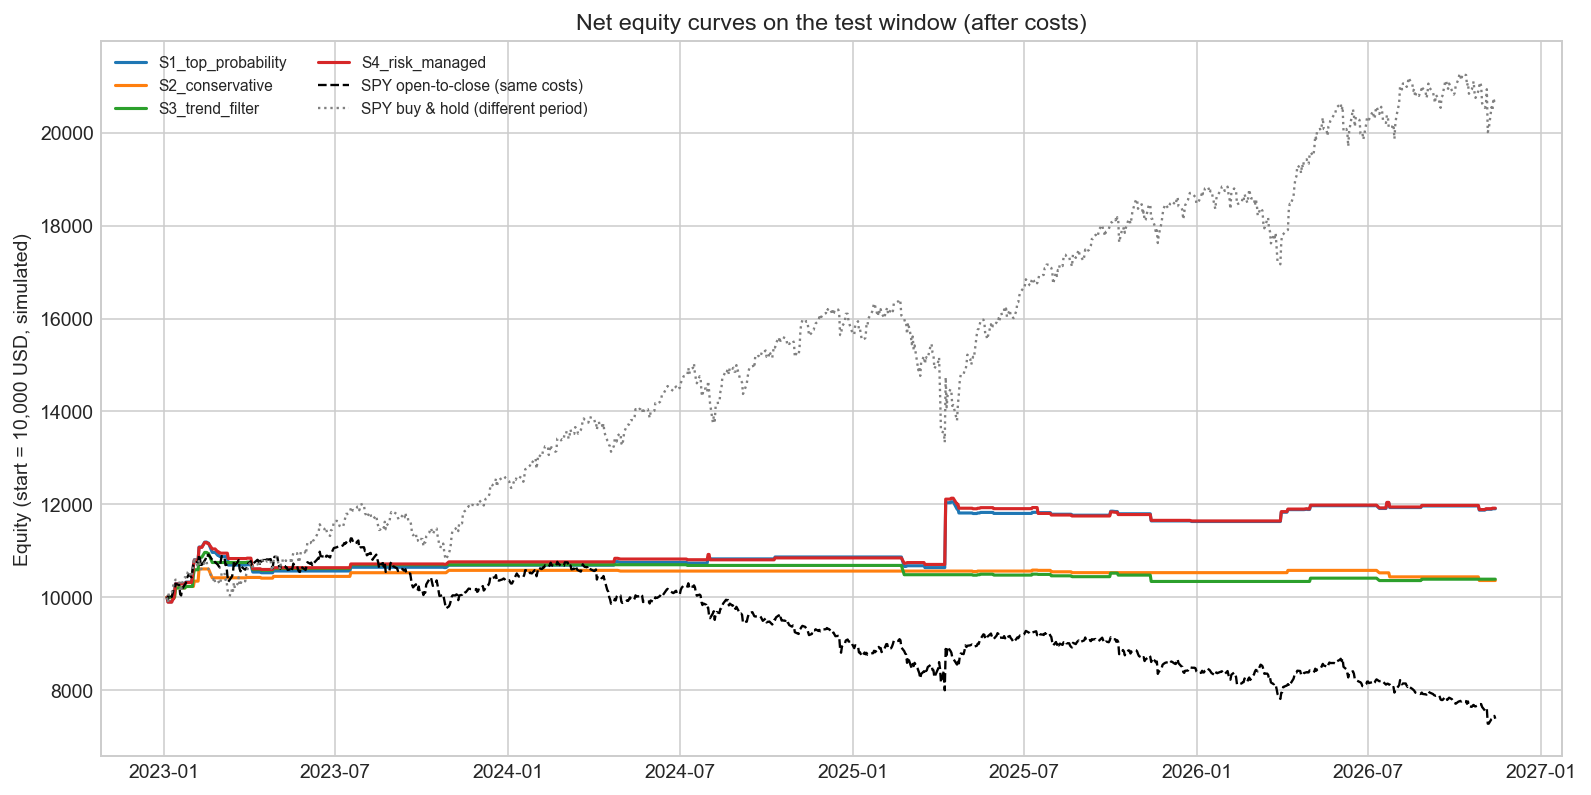

2026-11-15 19:42:04 | INFO    | Saved 12_drawdowns.png


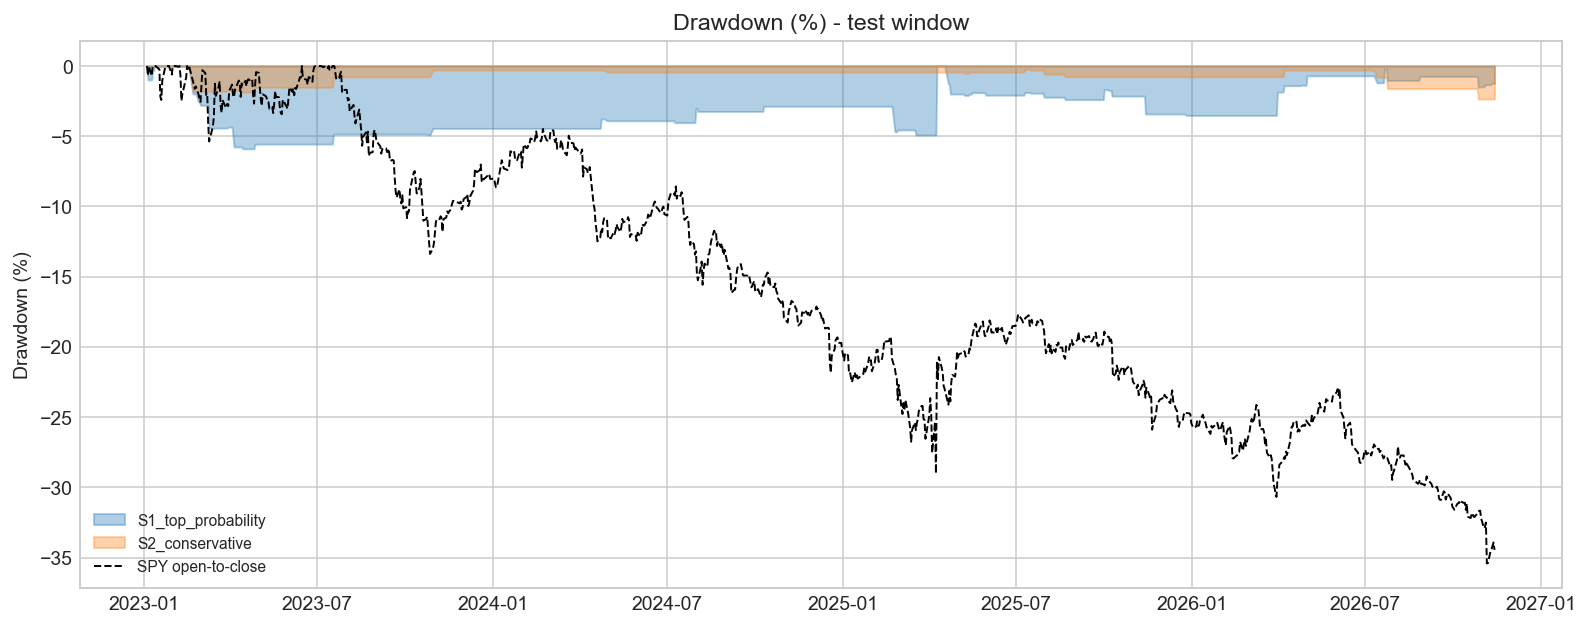

In [15]:
equity_figure = plots.plot_equity_curves(
    suite,
    {
        "SPY open-to-close (same costs)": benchmark_oc,
        "SPY buy & hold (different period)": benchmark_bh,
    },
)
display(Image(filename=str(ROOT / equity_figure), width=1000))

drawdown_figure = plots.plot_drawdowns(suite, {"SPY open-to-close": benchmark_oc})
display(Image(filename=str(ROOT / drawdown_figure), width=1000))

In [16]:
trades_s1 = suite["S1_top_probability"]["trades"]
print(f"S1 trades: {len(trades_s1)}")
print(f"average net return per trade: {trades_s1['net_ret'].mean():.4%}")
print(f"average win: {trades_s1.loc[trades_s1['net_ret'] > 0, 'net_ret'].mean():.4%} | "
      f"average loss: {trades_s1.loc[trades_s1['net_ret'] < 0, 'net_ret'].mean():.4%}")
trades_s1.head(10)

S1 trades: 63
average net return per trade: 0.2931%
average win: 1.0997% | average loss: -0.5395%


,signal_date,trade_date,ticker,prob,weight,gross_ret,cost,net_ret,stopped_out
0,2023-01-04,2023-01-05,QQQ,0.735399,1.0,-0.009317,0.0006,-0.009917,False
1,2023-01-09,2023-01-10,XLF,0.704143,1.0,0.007389,0.0006,0.006789,False
2,2023-01-11,2023-01-12,XLE,0.710120,1.0,0.012969,0.0006,0.012369,False
3,2023-01-12,2023-01-13,XLF,0.781177,1.0,0.020627,0.0006,0.020027,False
4,2023-01-23,2023-01-24,QQQ,0.783236,1.0,0.003689,0.0006,0.003089,False
5,2023-01-30,2023-01-31,XLF,0.719350,1.0,0.011622,0.0006,0.011022,False
6,2023-01-31,2023-02-01,XLK,0.720529,1.0,0.024290,0.0006,0.023690,False
7,2023-02-01,2023-02-02,IWM,0.823575,1.0,0.011785,0.0006,0.011185,False
8,2023-02-06,2023-02-07,XLE,0.804200,1.0,0.026013,0.0006,0.025413,False
9,2023-02-09,2023-02-10,QQQ,0.748204,1.0,0.000735,0.0006,0.000135,False


## 8. Latest simulated signal

The model used for the live signal is refit on **all** labelled data (after the
test evaluation, so it does not change any reported test number) and applied to
the most recent completed session.  `build_features.load_full_features()`
includes that last session, whose label is still unknown - which is exactly what
a real "next session" signal needs.

In [17]:
frame_full = build_features.load_full_features()
final_estimator = train_models.refit_on_all(
    sample, metadata, best_model, artifacts["best_params"].get(best_model)
)
latest_signal = train_models.predict_latest(frame_full, metadata, best_model, final_estimator)

latest_signal[["signal_session", "ticker", "prob_up_next_session", "vix_lag1", "close"]].round(4)

,signal_session,ticker,prob_up_next_session,vix_lag1,close
0,2026-11-13,XLF,0.7059,18.7,58.68
1,2026-11-13,XLE,0.6106,18.7,64.96
2,2026-11-13,IWM,0.6089,18.7,277.54
3,2026-11-13,SPY,0.5971,18.7,754.37
4,2026-11-13,QQQ,0.5408,18.7,679.89
5,2026-11-13,XLK,0.4600,18.7,170.28


In [18]:
top = latest_signal.iloc[0]
would_trade = bool(top["prob_up_next_session"] >= best_threshold)

print(f"Signal session : {top['signal_session']} (close)")
print(f"Execution      : next session OPEN -> CLOSE (simulated)")
print(f"Model          : {best_model} (threshold {best_threshold:.2f})")
print(f"Top ETF        : {top['ticker']}  p={top['prob_up_next_session']:.3f}")
print("SIMULATED intent:", "BUY at the next open" if would_trade else "stay in cash")
print("\nNo order is sent anywhere - the paper broker in src/broker.py refuses live trading.")

Signal session : 2026-11-13 (close)
Execution      : next session OPEN -> CLOSE (simulated)
Model          : xgboost (threshold 0.70)
Top ETF        : XLF  p=0.706
SIMULATED intent: BUY at the next open

No order is sent anywhere - the paper broker in src/broker.py refuses live trading.


## 9. What this notebook does **not** show

* No profitability promise: the test-window numbers are what they are, and the
  t-statistic of the average daily return is reported in `reports/summary.md`.
* The like-for-like benchmark trades every session and therefore pays costs
  every session; the gross comparison is the fairer test of signal quality.
* Buy & hold has a different holding period and is shown for context only.
* Costs, slippage and the intraday stop-loss fill are assumptions, not measured
  executions. See `docs/methodology.md` for the full limitations.

In [19]:
from src import report

report.write_summary(read_json(config.REPORTS_DIR / "metrics.json"))
report.write_rubric_checklist(read_json(config.REPORTS_DIR / "metrics.json"))

for path in [
    "reports/summary.md",
    "reports/metrics.json",
    "docs/rubric_checklist.md",
    "reports/pytest.xml",
]:
    target = ROOT / path
    print(f"{path:32s} {'OK' if target.exists() else 'missing'}")

2026-11-15 19:42:05 | INFO    | Wrote <project-root>\reports\summary.md


2026-11-15 19:42:05 | INFO    | Wrote <project-root>\docs\rubric_checklist.md


reports/summary.md               OK
reports/metrics.json             OK
docs/rubric_checklist.md         OK
reports/pytest.xml               OK


## 10. Reproduce from the command line

```powershell
python -m venv .venv
.venv\Scripts\Activate.ps1
pip install -r requirements.txt

python -m src.run_pipeline --mode live      # download + validate + train + backtest + reports
python -m src.run_pipeline --mode cached    # same, no network access
python -m pytest -q --junitxml=reports/pytest.xml
streamlit run src/dashboard.py              # optional monitoring dashboard
```

Next research steps (documented in `docs/methodology.md`): intraday bars for a
realistic stop-loss path, an explicit regime model, learning-to-rank across the
ETF cross-section, probability calibration, and walk-forward validation.